In [13]:
# libraries
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df_train = pd.read_csv('../data/train_orders.csv')

In [4]:
df_train.info()
df_train.isna().sum()
df_train.duplicated().sum()
df_train.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3214874 entries, 0 to 3214873
Data columns (total 7 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   order_id                int64  
 1   user_id                 int64  
 2   eval_set                object 
 3   order_number            int64  
 4   order_dow               int64  
 5   order_hour_of_day       int64  
 6   days_since_prior_order  float64
dtypes: float64(1), int64(5), object(1)
memory usage: 171.7+ MB


,order_id,user_id,order_number,order_dow,order_hour_of_day,days_since_prior_order
count,3.214874e+06,3.214874e+06,3.214874e+06,3.214874e+06,3.214874e+06,3.008665e+06
mean,1.710827e+06,1.029701e+05,1.719107e+01,2.776364e+00,1.344347e+01,1.070724e+01
std,9.875206e+05,5.953411e+04,1.779950e+01,2.041806e+00,4.226246e+00,8.954180e+00
min,2.000000e+00,1.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,8.556832e+05,5.138500e+04,5.000000e+00,1.000000e+00,1.000000e+01,4.000000e+00
50%,1.711120e+06,1.026620e+05,1.100000e+01,3.000000e+00,1.300000e+01,7.000000e+00
75%,2.566034e+06,1.543720e+05,2.400000e+01,5.000000e+00,1.600000e+01,1.500000e+01
max,3.421083e+06,2.062090e+05,9.900000e+01,6.000000e+00,2.300000e+01,3.000000e+01


In [5]:
df_train.duplicated().sum()

np.int64(0)

In [6]:
df_train.isna().sum()

order_id                       0
user_id                        0
eval_set                       0
order_number                   0
order_dow                      0
order_hour_of_day              0
days_since_prior_order    206209
dtype: int64

In [7]:
df_train[df_train['order_number'] == 1]['days_since_prior_order'].isna().all()

np.True_

-- Data set is clean
-- Start some eda

## EDA

In [11]:
df_train.tail(15)

,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
3214859,1285346,206208,prior,48,1,11,5.0
3214860,1882108,206208,prior,49,1,22,7.0
3214861,3154581,206209,prior,1,3,11,NaN
3214862,1889163,206209,prior,2,3,17,7.0
3214863,1542354,206209,prior,3,5,11,30.0
3214864,688306,206209,prior,4,1,10,30.0
3214865,2307371,206209,prior,5,4,15,3.0
3214866,3186442,206209,prior,6,0,16,3.0
3214867,550836,206209,prior,7,2,13,9.0
3214868,2129269,206209,prior,8,3,17,22.0


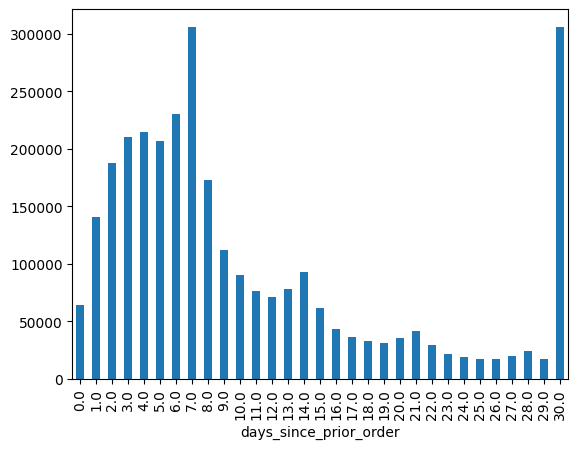

In [14]:
# get hist (indidivudal numbers) for each days since prior order
# are there a lot of 30's? is there a promotion or something that incentives ordering within 30 days?
df_train['days_since_prior_order'].value_counts().sort_index().plot(kind='bar')
plt.show()

-- Researched - 30+ days are just grouped into 30

-- Spikes at 7, 14, 21, 28. i.e. every week. These are consistent users. How to get every 28 day users into 14 day? 21 and 14 into 7?

-- Can have a variable - n*1week

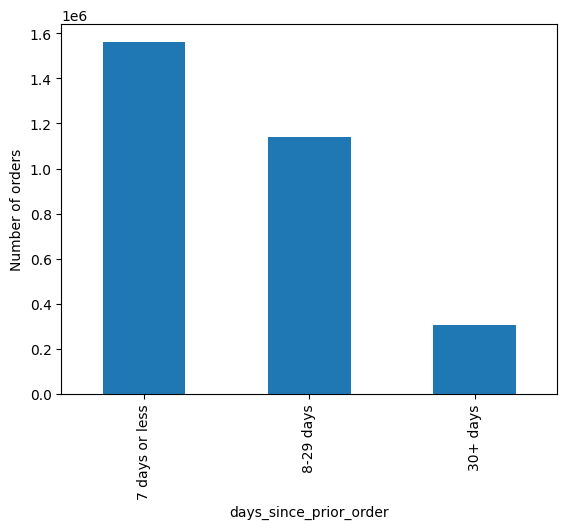

In [15]:
# bucket days since prior by large group frequency
groups = pd.cut(
    df_train['days_since_prior_order'],
    bins=[-1, 7, 29, 30],
    labels=['7 days or less', '8-29 days', '30+ days']
)

groups.value_counts(sort=False).plot(kind='bar')
plt.ylabel('Number of orders')
plt.show()

-- this first bucket are frequent users. how do we get the second bucket into the first? no - most orders are frequent orders, which is similar but different to frequent users.

-- we need to look at different stat for this - I think we want to look at users who are typically ordering weekly (7 days or less > 50% of orders), and users who are ordering 8-29 days out.

-- that 8-14 group is good too. I think we want to target that group. How do we get them from 'missing a week' to ordering next week?

-- create a variable weeks from previous order - 0 (same week), 1, 2, 3, 4 weeks or more.

-- And again, I think we really want to look at an individual user's typical behavior. Say someone typically always orders on Sunday, so 7 days since prior order. But they miss a Sunday, so one prior order is 14. Then we send them a coupon to come back, giving them a discount, when they were going to come back anyway. This actually incentivizes them to skip orders; this we don't want.

-- For this type of analysis we want median not mean - we don't want outliers to influence the center.

-- we'll also need to look at users by how many total orders.

In [17]:
df_train.tail(20)

,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
3214854,167903,206208,prior,43,4,14,3.0
3214855,2393201,206208,prior,44,6,16,2.0
3214856,3292671,206208,prior,45,2,11,3.0
3214857,3059777,206208,prior,46,1,10,13.0
3214858,2239861,206208,prior,47,3,4,9.0
3214859,1285346,206208,prior,48,1,11,5.0
3214860,1882108,206208,prior,49,1,22,7.0
3214861,3154581,206209,prior,1,3,11,NaN
3214862,1889163,206209,prior,2,3,17,7.0
3214863,1542354,206209,prior,3,5,11,30.0


In [19]:
## generate stat for median order by weeks
user_medians = df_train.groupby('user_id')['days_since_prior_order'].median()
user_medians

user_id
1         20.0
2         13.0
3         11.0
4         17.0
5         11.0
          ... 
206205    20.0
206206     3.0
206207     8.0
206208     7.0
206209    20.0
Name: days_since_prior_order, Length: 206209, dtype: float64

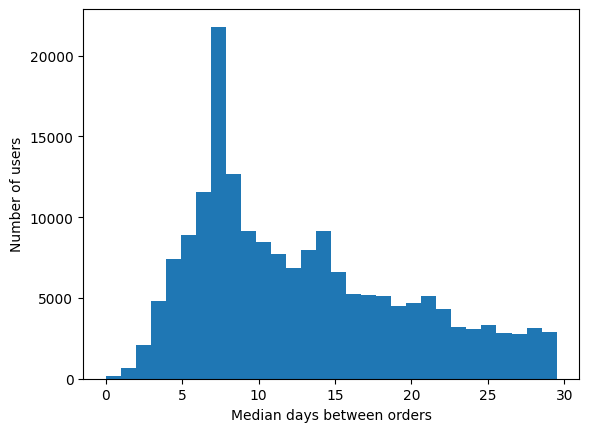

In [21]:
# how does this look graphically?
plt.hist(user_medians[user_medians < 30].dropna(), bins=30)
plt.xlabel('Median days between orders')
plt.ylabel('Number of users')
plt.show()

In [22]:
# just curious - size of order by day of week - I estimate that weekend and monday orders are bigger.
# argh, I need to join df's.

In [ ]:
# Well, I want to get to modeling. Then do another sprint. I just want a model that works.
# I want to cover every aspect of the analysis from sourcing to modeling.